# EDA 02 · Transactions: record quality

**Question.** Which transaction records are duplicated, incomplete or ambiguous, and what cleaning rules do w1 (tabular) and w2 (sequences) need?

**Fields.** `payment_method_id`, `payment_plan_days`, `plan_list_price`, `actual_amount_paid`, `is_auto_renew`, `transaction_date`, `membership_expire_date`, `is_cancel`, from `transactions` and `transactions_v2`.

**Population.** Records of the `fit` customers dated on or before 2017-01-31 (notebook 00). This notebook works **per record**; churn appears only where a cleaning choice changes a customer-level feature.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

EDA_DIR = next(p for p in (Path.cwd(), Path.cwd() / "eda") if (p / "_common.py").exists())
sys.path.insert(0, str(EDA_DIR))
import _common as C

pl.Config.set_tbl_rows(30); pl.Config.set_tbl_cols(14); pl.Config.set_tbl_width_chars(160)
pd.options.display.float_format = "{:,.4f}".format
pd.set_option("display.max_colwidth", None)

users = C.load_fit_population()
BASE = users["is_churn"].mean()
raw = C.scan_transactions(users).collect(engine="streaming")
print(f"records: {raw.height:,} | customers with records: {raw['msno'].n_unique():,} of {users.height:,}")

records: 11,336,661 | customers with records: 743,093 of 744,699


## 1. Sources

In [2]:
raw.group_by("source").agg(records=pl.len(), first=pl.col("transaction_date").min(),
                           last=pl.col("transaction_date").max()).sort("source")

source,records,first,last
i8,u32,i32,i32
1,11274174,20150101,20170131
2,62487,20150101,20170131


After the as-of filter, `transactions_v2` contributes only 0.6 % of the records: the history comes almost entirely from the first file. Both files cover the same dates up to the cutoff, so they must be concatenated and deduplicated together.

## 2. Exact duplicates

In [3]:
key = ["msno"] + C.TXN_COLS
dups = raw.filter(pl.struct(key).is_duplicated())
txn = raw.unique(subset=key, keep="first", maintain_order=True)
print(f"rows in duplicate groups: {dups.height:,} | extra copies removed: {raw.height - txn.height:,} "
      f"({(raw.height - txn.height) / raw.height:.3%})")
dups.group_by("source").agg(rows=pl.len())

rows in duplicate groups: 4,229 | extra copies removed: 2,149 (0.019%)


source,rows
i8,u32
1,4229


Exact duplicates are rare (about 2k extra copies, all inside the first file) and carry no information. Keeping the first copy is enough. Everything below uses the deduplicated table `txn`.

## 3. Missing plan fields: `payment_plan_days = 0` and `plan_list_price = 0`

In [4]:
txn = txn.with_columns(td=C.to_date("transaction_date"), ed=C.to_date("membership_expire_date"))
txn = txn.with_columns(duration=(pl.col("ed") - pl.col("td")).dt.total_days())
zero = txn.select(
    plan0_list0=((pl.col("payment_plan_days") == 0) & (pl.col("plan_list_price") == 0)).sum(),
    plan0_list_pos=((pl.col("payment_plan_days") == 0) & (pl.col("plan_list_price") > 0)).sum(),
    plan_pos_list0=((pl.col("payment_plan_days") > 0) & (pl.col("plan_list_price") == 0)).sum(),
)
zero

plan0_list0,plan0_list_pos,plan_pos_list0
u32,u32,u32
450166,0,39193


In [5]:
pz = txn.filter((pl.col("payment_plan_days") == 0) & (pl.col("plan_list_price") == 0))
print("amount actually paid on these records:")
print(pz.group_by("actual_amount_paid").agg(records=pl.len()).sort("records", descending=True).head(6))
print("days between transaction and expiry:")
print(pz.select([pl.col("duration").quantile(q).alias(f"p{int(q*100)}") for q in (.05, .25, .5, .75, .95)]))

amount actually paid on these records:
shape: (6, 2)
┌────────────────────┬─────────┐
│ actual_amount_paid ┆ records │
│ ---                ┆ ---     │
│ i16                ┆ u32     │
╞════════════════════╪═════════╡
│ 149                ┆ 414158  │
│ 119                ┆ 14889   │
│ 129                ┆ 14888   │
│ 150                ┆ 2939    │
│ 0                  ┆ 1305    │
│ 134                ┆ 504     │
└────────────────────┴─────────┘
days between transaction and expiry:
shape: (1, 5)
┌──────┬──────┬──────┬──────┬──────┐
│ p5   ┆ p25  ┆ p50  ┆ p75  ┆ p95  │
│ ---  ┆ ---  ┆ ---  ┆ ---  ┆ ---  │
│ f64  ┆ f64  ┆ f64  ┆ f64  ┆ f64  │
╞══════╪══════╪══════╪══════╪══════╡
│ 30.0 ┆ 30.0 ┆ 31.0 ┆ 31.0 ┆ 54.0 │
└──────┴──────┴──────┴──────┴──────┘


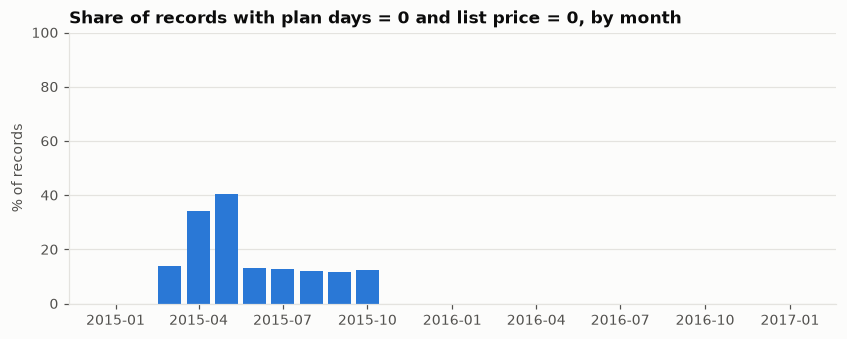

last month with such records: 2015-10-01 00:00:00


In [6]:
monthly = (txn.with_columns(month=pl.col("td").dt.truncate("1mo"),
                            missing_plan=(pl.col("payment_plan_days") == 0) & (pl.col("plan_list_price") == 0))
              .group_by("month").agg(records=pl.len(), missing_share=pl.col("missing_plan").mean())
              .sort("month").to_pandas())
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(monthly["month"], monthly["missing_share"] * 100, width=25, color=C.COLORS["series"])
ax.set_ylabel("% of records"); ax.set_ylim(0, 100)
ax.set_title("Share of records with plan days = 0 and list price = 0, by month", loc="left")
C.save_fig(fig, "02_missing_plan_by_month"); plt.show()
print("last month with such records:", monthly.loc[monthly.missing_share > 0, "month"].max())

In [7]:
affected = pz.select("msno").unique()
print(f"customers with at least one such record: {affected.height:,} ({affected.height / users.height:.1%} of fit)")

customers with at least one such record: 231,851 (31.1% of fit)


- 450k records (4 % of the history) have `payment_plan_days = 0` **and** `plan_list_price = 0`, yet almost all were paid at a normal monthly price (149, 129, 119) and last about 30 days. They are not free plans: the two plan fields are **missing**, and the problem is confined to **March–October 2015**. It still touches **31 % of the fit customers**, everyone with history from that period.
- The legacy EDA's "some users pay more than the list price" is this artifact: with the list price stored as 0, every paid amount looks like an overpayment. Once these records are excluded, `paid > list` happens 39 times.
- Current w1 features that average or sum `plan_list_price`, `payment_plan_days` or `list - paid` over the whole history (`average_amount_charged`, `sum_list_price`, `average_plan`, `last_discount`, `difference`, `plan_coverage_ratio`) treat these zeros as real values for the long-tenure customers listed above.

**Rule:** when both fields are 0, set them to **null** (unknown), keep `actual_amount_paid`, and exclude the record from any list-price or plan-length statistic.

## 4. Free and discounted records

With the missing-field records set aside, the remaining records fall into four price types.

In [8]:
txn = txn.with_columns(
    plan_fields_missing=(pl.col("payment_plan_days") == 0) & (pl.col("plan_list_price") == 0))
txn = txn.with_columns(price_type=
    pl.when(pl.col("plan_fields_missing")).then(pl.lit("plan fields missing"))
    .when(pl.col("actual_amount_paid") == 0).then(pl.lit("free"))
    .when(pl.col("actual_amount_paid") < pl.col("plan_list_price")).then(pl.lit("discounted"))
    .when(pl.col("actual_amount_paid") > pl.col("plan_list_price")).then(pl.lit("above list"))
    .otherwise(pl.lit("full price")))
(txn.group_by("price_type").agg(records=pl.len(), share=pl.len() / txn.height,
                                cancel_share=pl.col("is_cancel").mean())
    .sort("records", descending=True))

price_type,records,share,cancel_share
str,u32,f64,f64
"""full price""",10625817,0.937475,0.016014
"""plan fields missing""",450166,0.039716,0.008621
"""discounted""",172988,0.015262,0.000491
"""free""",85502,0.007544,0.135108
"""above list""",39,0.000003,0.666667


In [9]:
for kind in ("free", "discounted"):
    print(kind)
    print(txn.filter(pl.col("price_type") == kind)
             .group_by("payment_plan_days", "plan_list_price", "actual_amount_paid").agg(records=pl.len())
             .sort("records", descending=True).head(6))

free
shape: (6, 4)
┌───────────────────┬─────────────────┬────────────────────┬─────────┐
│ payment_plan_days ┆ plan_list_price ┆ actual_amount_paid ┆ records │
│ ---               ┆ ---             ┆ ---                ┆ ---     │
│ i16               ┆ i16             ┆ i16                ┆ u32     │
╞═══════════════════╪═════════════════╪════════════════════╪═════════╡
│ 30                ┆ 149             ┆ 0                  ┆ 40486   │
│ 7                 ┆ 0               ┆ 0                  ┆ 32258   │
│ 31                ┆ 149             ┆ 0                  ┆ 5273    │
│ 10                ┆ 0               ┆ 0                  ┆ 3625    │
│ 1                 ┆ 0               ┆ 0                  ┆ 2015    │
│ 30                ┆ 180             ┆ 0                  ┆ 421     │
└───────────────────┴─────────────────┴────────────────────┴─────────┘
discounted
shape: (4, 4)
┌───────────────────┬─────────────────┬────────────────────┬─────────┐
│ payment_plan_days ┆ plan_list_p

- **Discounted** records are almost all one promotion: the 30-day, 149 plan sold at 119.
- **Free** records are either 7-day trials (`list = 0`) or a 30-day plan billed at 0 (a free month).
- `above list` is negligible.

These types are a cleaner basis for discount features than the raw `list - paid` difference: "had a free trial", "on a promotion" and "paid full price" are different situations.

## 5. Dates

In [10]:
print("expiry before transaction date, by is_cancel:")
print(txn.filter(pl.col("duration") < 0).group_by("is_cancel")
         .agg(records=pl.len(), median_days=pl.col("duration").median()).sort("is_cancel"))
print("\nexpiry year distribution (tails):")
print(txn.group_by(pl.col("ed").dt.year().alias("expire_year")).agg(records=pl.len())
         .sort("expire_year").filter((pl.col("expire_year") < 2015) | (pl.col("expire_year") > 2017)))

expiry before transaction date, by is_cancel:
shape: (2, 3)
┌───────────┬─────────┬─────────────┐
│ is_cancel ┆ records ┆ median_days │
│ ---       ┆ ---     ┆ ---         │
│ i8        ┆ u32     ┆ f64         │
╞═══════════╪═════════╪═════════════╡
│ 0         ┆ 2239    ┆ -30.0       │
│ 1         ┆ 43063   ┆ -1.0        │
└───────────┴─────────┴─────────────┘

expiry year distribution (tails):


shape: (13, 2)
┌─────────────┬─────────┐
│ expire_year ┆ records │
│ ---         ┆ ---     │
│ i32         ┆ u32     │
╞═════════════╪═════════╡
│ 1970        ┆ 110     │
│ 1999        ┆ 1       │
│ 2007        ┆ 1       │
│ 2009        ┆ 2       │
│ 2012        ┆ 3       │
│ 2013        ┆ 2179    │
│ 2014        ┆ 2894    │
│ 2018        ┆ 15798   │
│ 2019        ┆ 3575    │
│ 2020        ┆ 945     │
│ 2021        ┆ 297     │
│ 2022        ┆ 41      │
│ 2023        ┆ 1       │
└─────────────┴─────────┘


- Expiry before the transaction date is almost always a **cancellation** (43k records, median −1 day): cancelling sets the expiry to around the cancellation date. About 2k non-cancel records do it too (median −30 days); they are rare enough to be treated as invalid expiries.
- **Expiry year 1970** (110 records) is a zero timestamp, not a date → invalid.
- Expiries in 2018–2023 exist (about 20k records). Section 5.1 shows most of them are long or stacked memberships, not errors.

### 5.1 Expiry is cumulative, not the plan length

For paid, non-cancelled records, compare the days from transaction to expiry with the plan length.

shape: (1, 8)
┌──────┬──────┬─────┬─────┬─────┬──────┬───────┬───────┐
│ p1   ┆ p5   ┆ p25 ┆ p50 ┆ p75 ┆ p95  ┆ p99   ┆ p99.9 │
│ ---  ┆ ---  ┆ --- ┆ --- ┆ --- ┆ ---  ┆ ---   ┆ ---   │
│ f64  ┆ f64  ┆ f64 ┆ f64 ┆ f64 ┆ f64  ┆ f64   ┆ f64   │
╞══════╪══════╪═════╪═════╪═════╪══════╪═══════╪═══════╡
│ -2.0 ┆ -1.0 ┆ 0.0 ┆ 1.0 ┆ 1.0 ┆ 22.0 ┆ 364.0 ┆ 965.0 │
└──────┴──────┴─────┴─────┴─────┴──────┴───────┴───────┘
excess > 31 days: 2.64% of records | > 365 days: 103,619


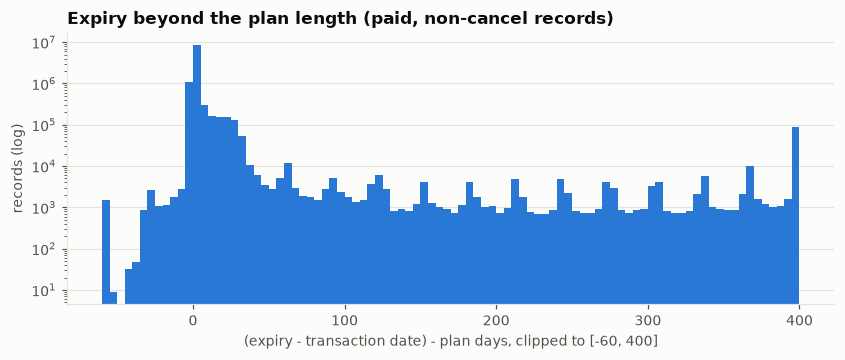

In [11]:
paid = txn.filter((pl.col("payment_plan_days") > 0) & (pl.col("is_cancel") == 0))
paid = paid.with_columns(excess=pl.col("duration") - pl.col("payment_plan_days"))
print(paid.select([pl.col("excess").quantile(q).alias(f"p{q*100:g}") for q in (.01, .05, .25, .5, .75, .95, .99, .999)]))
print(f"excess > 31 days: {(paid['excess'] > 31).mean():.2%} of records | > 365 days: {(paid['excess'] > 365).sum():,}")
ex = paid.select(pl.col("excess").clip(-60, 400)).to_series().to_numpy()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(ex, bins=np.arange(-60, 405, 5), color=C.COLORS["series"])
ax.set_yscale("log"); ax.set_xlabel("(expiry - transaction date) - plan days, clipped to [-60, 400]")
ax.set_ylabel("records (log)"); ax.set_title("Expiry beyond the plan length (paid, non-cancel records)", loc="left")
C.save_fig(fig, "02_expiry_excess"); plt.show()

For the bulk of the records (p5–p75) the expiry is the transaction date plus the plan, ±1 day; 2.6 % exceed it by more than a month and 104k records by more than a year. The long right tail is **stacking**: a renewal charged while the previous period is still running extends the existing expiry, so the gap from the transaction to the expiry can be a year or more. Consequence: the current w1 `duration = expiry - transaction_date` (and `more_than_30`, `plan_coverage_ratio` built from it) mixes plan length with how far ahead the customer is paid. Plan length should come from `payment_plan_days`, and "paid ahead" should be its own measure (`days_to_expire` at the cutoff, notebook 03).

## 6. What does a cancellation record do?

In [12]:
seq = txn.sort("msno", "transaction_date", "_ord").with_columns(
    prev_ed=pl.col("membership_expire_date").shift(1).over("msno"))
canc = seq.filter(pl.col("is_cancel") == 1)
canc.select(
    records=pl.len(),
    expiry_moved_back=(pl.col("membership_expire_date") < pl.col("prev_ed")).mean(),
    expiry_unchanged=(pl.col("membership_expire_date") == pl.col("prev_ed")).mean(),
    expiry_moved_forward=(pl.col("membership_expire_date") > pl.col("prev_ed")).mean(),
    no_previous_record=pl.col("prev_ed").is_null().mean(),
    expiry_equals_txn_date=(pl.col("membership_expire_date") == pl.col("transaction_date")).mean(),
    auto_renew_on=(pl.col("is_auto_renew") == 1).mean(),
)

records,expiry_moved_back,expiry_unchanged,expiry_moved_forward,no_previous_record,expiry_equals_txn_date,auto_renew_on
u32,f64,f64,f64,f64,f64,f64
185710,0.62142,0.321889,0.056691,0.031835,0.469652,1.0


A cancellation is a **state change**, not a payment: 62 % move the expiry back (47 % to the cancellation date itself), 32 % leave it unchanged, and only 6 % move it forward.

**Every cancellation record has `is_auto_renew = 1`.** Cancelling means switching off the auto-renewal of an auto-renewing plan. The combination `is_auto_renew = 0 & is_cancel = 1` never occurs, so the current w1 flag `not_autorenew_cancel` is a constant (it is the "constant feature" the legacy notebooks reported). It must not be counted as a transaction in volume features (`transaction_count`, sums of paid amounts), and its expiry replaces the previous one.

## 7. Several records on the same day

The source order `_ord` is the row order of the file, not a time of day. When a customer has several records on one day, "the last record" is not well defined.

In [13]:
txn = txn.with_columns(k_day=pl.len().over("msno", "transaction_date"))
multi = txn.filter(pl.col("k_day") > 1).sort("msno", "transaction_date", "_ord")
groups = multi.group_by("msno", "transaction_date").agg(
    pattern=pl.col("is_cancel").cast(pl.String).str.join(""),
    last_is_max_expiry=pl.col("membership_expire_date").last() == pl.col("membership_expire_date").max())
print(f"customer-days with > 1 record: {groups.height:,} | customers: {groups['msno'].n_unique():,} "
      f"({groups['msno'].n_unique() / users.height:.1%} of fit)")
print(f"last record by file order has the latest expiry in {groups['last_is_max_expiry'].mean():.1%} of them")
groups.group_by("pattern").agg(days=pl.len()).sort("days", descending=True).head(6)

customer-days with > 1 record: 134,242 | customers: 97,292 (13.1% of fit)
last record by file order has the latest expiry in 52.9% of them


pattern,days
str,u32
"""10""",41584
"""00""",40990
"""01""",40883
"""010""",2153
"""001""",2143
"""100""",2137


What matters for the models is the **last transaction day before the cutoff**, because it defines the current subscription state.

In [14]:
last_day = txn.filter(pl.col("transaction_date") == pl.col("transaction_date").max().over("msno"))
ld = (last_day.sort("_ord").group_by("msno").agg(
        k=pl.len(),
        ord_last_cancel=pl.col("is_cancel").last(),
        any_cancel=pl.col("is_cancel").max(),
        all_cancel=pl.col("is_cancel").min(),
        ord_last_expire=pl.col("membership_expire_date").last(),
        max_expire=pl.col("membership_expire_date").max())
      .join(users, on="msno"))
amb = ld.filter(pl.col("k") > 1)
print(f"customers whose last transaction day has > 1 record: {amb.height:,} ({amb.height / users.height:.1%})")
print(f"  file-order rule and 'any cancel' disagree for {(amb['ord_last_cancel'] != amb['any_cancel']).sum():,}")
print(f"  file-order rule and 'latest expiry' disagree for {(amb['ord_last_expire'] != amb['max_expire']).sum():,}")
mixed = amb.filter(pl.col("any_cancel") != pl.col("all_cancel")).with_columns(
    file_order_says=pl.when(pl.col("ord_last_cancel") == 1).then(pl.lit("cancel last")).otherwise(pl.lit("payment last")))
C.churn_rate_by(mixed, "file_order_says")[["file_order_says", "n", "churn_rate", "ci_low", "ci_high"]]

customers whose last transaction day has > 1 record: 8,736 (1.2%)
  file-order rule and 'any cancel' disagree for 3,058
  file-order rule and 'latest expiry' disagree for 4,130


,file_order_says,n,churn_rate,ci_low,ci_high
0,cancel last,3031,0.2062,0.1922,0.2210
1,payment last,3058,0.2116,0.1975,0.2264


In [15]:
single = ld.filter(pl.col("k") == 1).with_columns(state=pl.when(pl.col("any_cancel") == 1).then(pl.lit("single: cancel"))
                                                       .otherwise(pl.lit("single: payment")))
mixed_all = mixed.with_columns(state=pl.lit("same day: cancel + payment"))
cmp_tbl = C.churn_rate_by(pl.concat([single.select("state", "is_churn"), mixed_all.select("state", "is_churn")]), "state")
cmp_tbl[["state", "n", "churn_rate", "ci_low", "ci_high"]]

,state,n,churn_rate,ci_low,ci_high
0,same day: cancel + payment,6089,0.2089,0.1989,0.2193
1,single: cancel,6762,0.8262,0.8170,0.8351
2,single: payment,727595,0.0530,0.0525,0.0535



- 13 % of the customers have at least one day with several records, typically a cancellation and a payment (`10`, `01`) or two payments (`00`). In those days the last record by file order holds the latest expiry only 53 % of the time: **file order is not time order**.
- For the current state this affects **8,736 customers (1.2 %)**, those whose last transaction day has several records. When that day mixes a cancellation and a payment (6,089 customers), churn is 21 % **whatever the file order says** (20.6 % if the cancel is last, 21.2 % if the payment is last). The order carries no information.
- The mixed day is a state of its own, between a lone payment (5.3 %) and a lone cancellation (83 %). Picking "the last record" turns these customers into one of the extremes at random.

**Rule:** collapse the records of each day before taking "the last state": `last_day_has_cancel`, `last_day_has_payment` (hence a 3-level last-day state: payment / cancel / cancel + payment) and, for the expiry, the latest expiry of that day. w2 already marks this case as `tx_state_ambiguous`; w1 resolves it silently by file order.


## 8. Payment methods and plan catalogue

In [16]:
pm = txn.group_by("payment_method_id").agg(records=pl.len(), customers=pl.col("msno").n_unique()).sort("records", descending=True)
print(f"payment methods: {pm.height} | methods with < 1,000 customers: {(pm['customers'] < 1000).sum()} "
      f"(covering {pm.filter(pl.col('customers') < 1000)['records'].sum() / txn.height:.2%} of records)")
pm.head(10)

payment methods: 38 | methods with < 1,000 customers: 17 (covering 0.55% of records)


payment_method_id,records,customers
i8,u32,u32
41,6660478,436338
40,1145077,70484
39,843969,55902
37,581886,33455
38,524536,70554
34,468824,23260
36,392937,61066
33,228826,12601
31,161535,8566


In [17]:
cat = (txn.filter(~pl.col("plan_fields_missing"))
          .group_by("payment_plan_days", "plan_list_price").agg(records=pl.len())
          .with_columns(share=pl.col("records") / pl.col("records").sum(),
                        price_per_30d=(pl.col("plan_list_price") / pl.col("payment_plan_days") * 30).round(1))
          .sort("records", descending=True))
print(f"distinct (plan days, list price) pairs: {cat.height}; top 6 cover {cat.head(6)['share'].sum():.1%}")
cat.head(12)

distinct (plan days, list price) pairs: 83; top 6 cover 98.6%


payment_plan_days,plan_list_price,records,share,price_per_30d
i16,i16,u32,f64,f64
30,149,6047209,0.555588,149.0
30,99,3181617,0.292311,99.0
30,129,693808,0.063744,129.0
31,149,352548,0.03239,144.2
30,180,336374,0.030904,180.0
30,150,120326,0.011055,150.0
30,100,34305,0.003152,100.0
7,0,32258,0.002964,0.0
30,119,18414,0.001692,119.0


- 38 payment methods, heavily concentrated (method 41 alone is most of the records); the rare ones should be grouped before encoding (notebook 03 decides the threshold on the *last* method).
- The plan catalogue is small: a handful of 30-day prices (99, 129, 149, 180), 7-day free trials and a few long plans (195, 410 days). Price per 30 days puts long and short plans on one scale.

## 9. Conclusions


The transaction table is clean in the obvious places (duplicates, prices) and dirty in the places that matter for features:

1. **Missing plan fields in 2015** (4 % of records, 31 % of customers): zeros that are really nulls. Every history feature built on list price or plan length is affected.
2. **Expiry is cumulative**: `expiry - transaction date` measures plan length only for short, non-stacked periods. Plan length and "paid ahead" must be separate features.
3. **Cancellations are state changes** of auto-renewing plans, not payments, and `not_autorenew_cancel` is constant.
4. **Same-day records have no order**: state features must be computed on days, not on rows.
5. Prices form a small catalogue; discounts are one promotion (149 → 119) plus free trials and free months.


In [18]:
decisions = C.write_decisions("02", "Transactions: record quality", [
    {"finding": "2,149 exact duplicate records (0.02 %), all in the first file",
     "decision": "Concatenate both files, drop exact duplicates on msno + 8 fields, keep first",
     "kind": "cleaning"},
    {"finding": "450k records (Mar-Oct 2015) have plan days = 0 and list price = 0 but were paid ~149 for ~30 days; 31 % of customers affected",
     "decision": "Set plan days and list price to null on those records (keep amount paid); exclude them from list-price, plan-length and discount statistics",
     "kind": "cleaning"},
    {"finding": "'Paid above list price' is an artifact of the missing list price (39 real cases)",
     "decision": "Drop `difference` (mean paid - mean list) and `last_discount` as defined today; use price types instead",
     "kind": "drop"},
    {"finding": "Price types: full 94 %, missing fields 4 %, promotion 149->119 1.5 %, free (7-day trials, free months) 0.8 %",
     "decision": "Record-level `price_type` (full / discounted / free / unknown) as the basis for discount features (notebooks 03-04)",
     "kind": "new feature"},
    {"finding": "Expiry 1970 (110 records) and non-cancel records expiring before the transaction (2.2k)",
     "decision": "Set those expiries to null (invalid); cancellation records may legitimately expire before the transaction date",
     "kind": "cleaning"},
    {"finding": "Expiry is cumulative (stacked renewals): expiry - transaction date exceeds the plan by > 1 year for 104k records",
     "decision": "Drop `duration`, `more_than_30` and `plan_coverage_ratio` as defined today; plan length from `payment_plan_days`, paid-ahead from `days_to_expire` at the cutoff",
     "kind": "drop"},
    {"finding": "Cancellation = switching off auto-renew (all have is_auto_renew = 1); 62 % move the expiry back",
     "decision": "Cancellations are state changes: excluded from payment counts/sums; their expiry replaces the previous one",
     "kind": "cleaning"},
    {"finding": "`is_auto_renew = 0 & is_cancel = 1` never occurs",
     "decision": "Drop the constant `not_autorenew_cancel`",
     "kind": "drop"},
    {"finding": "File order is not time order within a day; 1.2 % of customers have a mixed cancel + payment last day (21 % churn, independent of order)",
     "decision": "Collapse records per day before deriving state: last-day state = payment / cancel / cancel + payment; last expiry = latest expiry of that day",
     "kind": "cleaning"},
    {"finding": "38 payment methods; 17 have < 1,000 customers (0.55 % of records)",
     "decision": "Group rare methods into `other` before encoding (threshold fixed in notebook 03 on the last method)",
     "kind": "transformation"},
])
decisions

,finding,decision,kind
0,"2,149 exact duplicate records (0.02 %), all in the first file","Concatenate both files, drop exact duplicates on msno + 8 fields, keep first",cleaning
1,450k records (Mar-Oct 2015) have plan days = 0 and list price = 0 but were paid ~149 for ~30 days; 31 % of customers affected,"Set plan days and list price to null on those records (keep amount paid); exclude them from list-price, plan-length and discount statistics",cleaning
2,'Paid above list price' is an artifact of the missing list price (39 real cases),Drop `difference` (mean paid - mean list) and `last_discount` as defined today; use price types instead,drop
3,"Price types: full 94 %, missing fields 4 %, promotion 149->119 1.5 %, free (7-day trials, free months) 0.8 %",Record-level `price_type` (full / discounted / free / unknown) as the basis for discount features (notebooks 03-04),new feature
4,Expiry 1970 (110 records) and non-cancel records expiring before the transaction (2.2k),Set those expiries to null (invalid); cancellation records may legitimately expire before the transaction date,cleaning
5,Expiry is cumulative (stacked renewals): expiry - transaction date exceeds the plan by > 1 year for 104k records,"Drop `duration`, `more_than_30` and `plan_coverage_ratio` as defined today; plan length from `payment_plan_days`, paid-ahead from `days_to_expire` at the cutoff",drop
6,Cancellation = switching off auto-renew (all have is_auto_renew = 1); 62 % move the expiry back,Cancellations are state changes: excluded from payment counts/sums; their expiry replaces the previous one,cleaning
7,`is_auto_renew = 0 & is_cancel = 1` never occurs,Drop the constant `not_autorenew_cancel`,drop
8,"File order is not time order within a day; 1.2 % of customers have a mixed cancel + payment last day (21 % churn, independent of order)",Collapse records per day before deriving state: last-day state = payment / cancel / cancel + payment; last expiry = latest expiry of that day,cleaning
9,"38 payment methods; 17 have < 1,000 customers (0.55 % of records)",Group rare methods into `other` before encoding (threshold fixed in notebook 03 on the last method),transformation


---
**Previous:** `01_members.ipynb` · **Next:** `03_transactions_state.ipynb`